# 04 - Fundamental risk model, OOS validation, optimisation and attribution (SYNTHETIC)

Sigma = B F B' + D, estimated from cross-sectional WLS factor returns; forecasts are made at t for month t+1 using only information available at t. The optimiser is a score-risk trade-off (scores are not calibrated expected returns). Strategies are executed through the project-02 backtester with next-open fills and 10 bps one-way costs. The hold-out is not used.

In [1]:
import logging

import pandas as pd
from IPython.display import Image, display

from factors import pipeline as pl
from factors.data import DataUnavailableError  # noqa: F401 - used by the real-data cells

logging.basicConfig(level=logging.WARNING)
pd.set_option("display.width", 160, "display.max_columns", 20)

def show(ctx, nn, name):
    display(Image(filename=str(ctx.fig(nn, name))))

In [2]:
syn = pl.Context('synthetic', 'fast')
r = pl.stage_risk_and_portfolio(syn)
r['bias'][r['bias'].period == 'all'][['group', 'n', 'bias', 'ci_low', 'ci_high']].round(3)

,group,n,bias,ci_low,ci_high
10,equal_weight,62,1.088,0.926,1.320
11,optimised,46,1.088,0.904,1.366
12,random (20),1240,1.095,1.054,1.140
13,simple_tilt,46,1.050,0.872,1.319


In [3]:
r['tear'][['strategy', 'period', 'ann_return', 'ann_vol', 'max_drawdown', 'tracking_error', 'info_ratio']].round(3)

,strategy,period,ann_return,ann_vol,max_drawdown,tracking_error,info_ratio
0,ew,validation,-0.027,0.195,-0.289,NaN,NaN
1,ew,oos,0.083,0.197,-0.205,NaN,NaN
2,tilt,validation,-0.098,0.212,-0.374,0.083,-0.865
3,tilt,oos,0.137,0.214,-0.216,0.084,0.615
4,opt,validation,-0.042,0.192,-0.304,0.020,-0.790
5,opt,oos,0.099,0.194,-0.214,0.020,0.686


In [4]:
att = r['attribution']
t = att.table()
print('sum of contributions =', t.vol_contrib_monthly.sum(), ' sigma =', att.sigma)
t.round(5)

sum of contributions = 0.0500878450416965  sigma = 0.0500878450416965


,exposure,vol_contrib_monthly,var_contrib_monthly,pct_of_sigma,vol_contrib_annual
source,,,,,
market,1.00000,0.04874,0.00244,0.97312,0.16885
ind_ConsDisc,0.15146,0.00127,0.00006,0.02528,0.00439
ind_Energy,0.16009,0.00107,0.00005,0.02133,0.00370
ind_Financials,0.17818,0.00021,0.00001,0.00418,0.00072
ind_Health,0.12694,-0.00064,-0.00003,-0.01277,-0.00222
ind_Industrials,0.07003,-0.00004,-0.00000,-0.00071,-0.00012
ind_Materials,0.08877,0.00061,0.00003,0.01219,0.00211
ind_Staples,0.12092,-0.00037,-0.00002,-0.00730,-0.00127
ind_Tech,0.10361,-0.00003,-0.00000,-0.00050,-0.00009


In [5]:
r['olog'][['date', 'status', 'solver', 'fallback_used', 'chk_te_monthly', 'chk_turnover_one_way', 'violations']].tail()

,date,status,solver,fallback_used,chk_te_monthly,chk_turnover_one_way,violations
42,2019-11-29,optimal,CLARABEL,False,0.005774,0.045942,
43,2019-12-31,optimal,CLARABEL,False,0.005774,0.060101,
44,2020-01-31,optimal,CLARABEL,False,0.005774,0.062223,
45,2020-02-28,optimal,CLARABEL,False,0.005774,0.062535,
46,2020-03-31,optimal,CLARABEL,False,0.005774,0.118968,


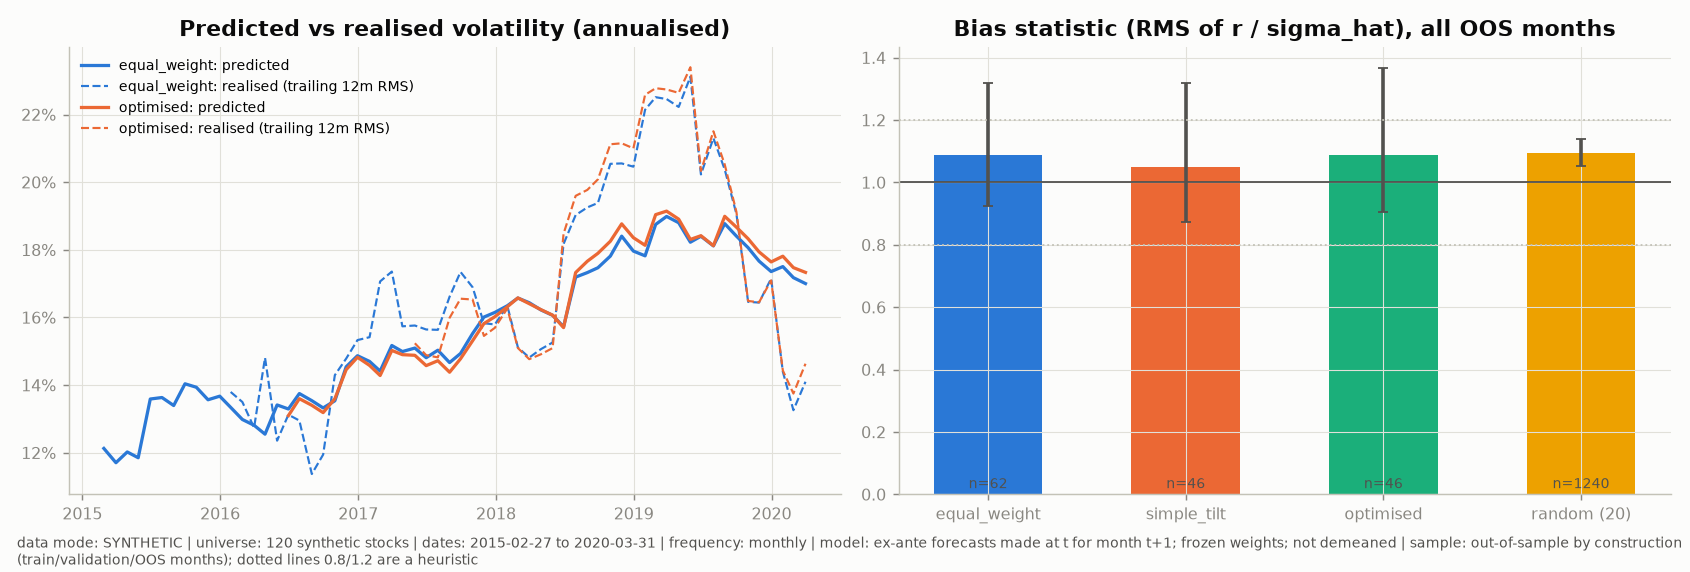

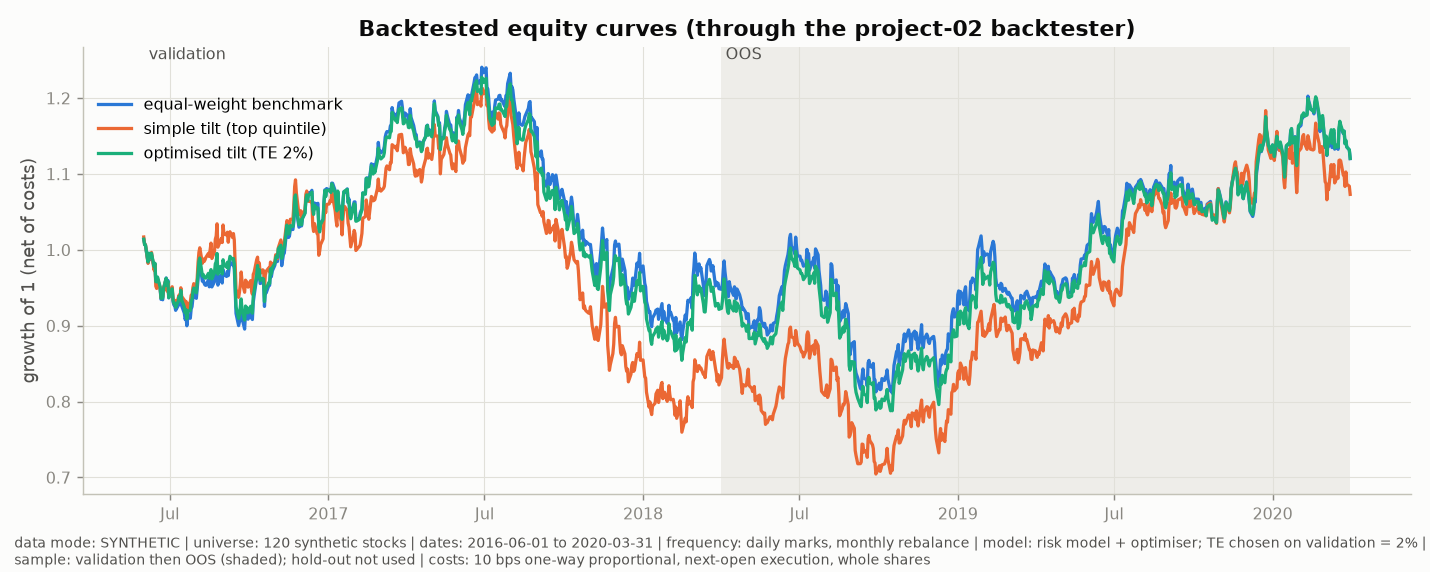

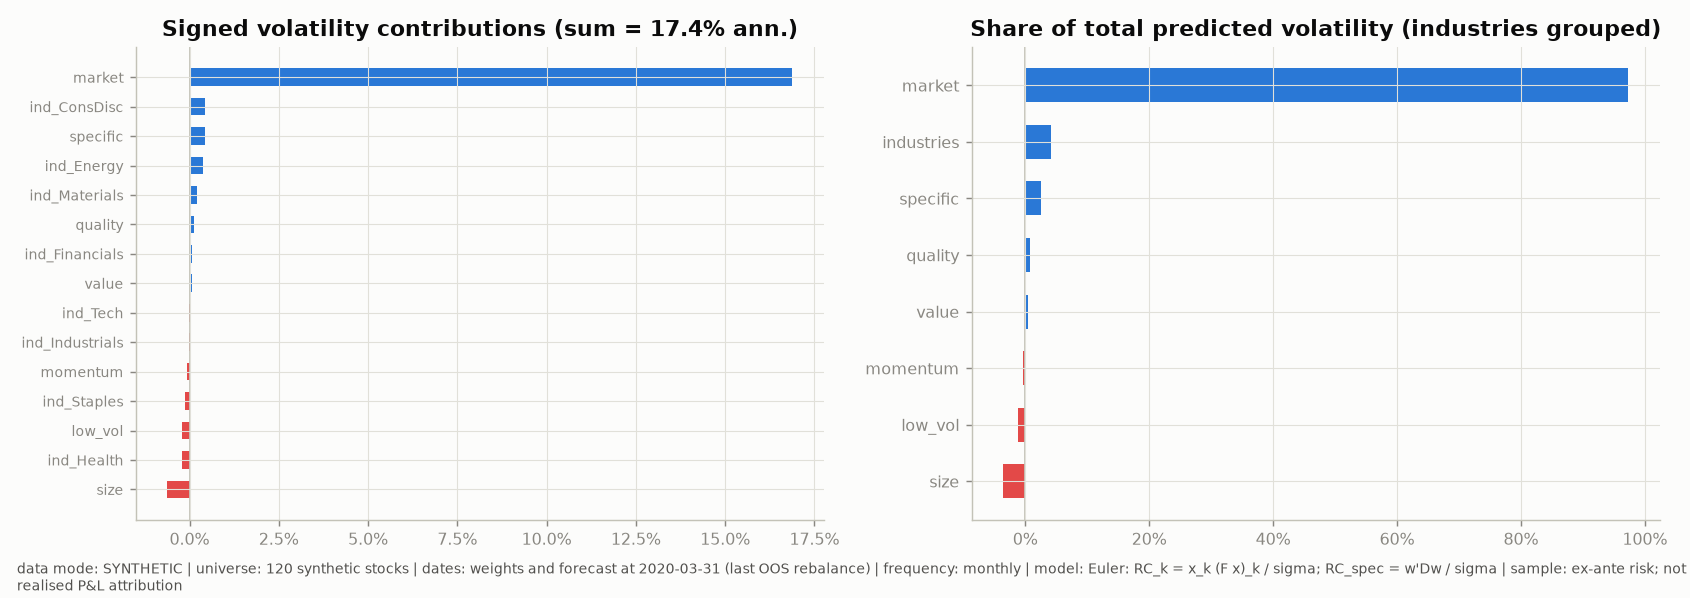

In [6]:
for nn, name in [('12', 'predicted_vs_realised_vol'), ('14', 'equity_curves'), ('17', 'risk_contributions_signed')]:
    show(syn, nn, name)